# Glyph default colours: before vs. proposals

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import eunoia

out = Path("glyph_defaults")
out.mkdir(exist_ok=True)
fit = eunoia.euler(
    {"A": 12, "B": 9, "C": 7, "A&B": 5, "A&C": 4, "B&C": 3, "A&B&C": 2}, seed=1
)
variants = {
    "before": {"tint": 0.45, "edge_tint": -0.35, "linewidth": 0.5},
    "option1": {"tint": 0.30, "edge_tint": -0.35, "linewidth": 0.5},
    "option2": {"tint": 0.30, "edge_tint": -0.45, "linewidth": 0.6},
    "option3": {"tint": 0.20, "edge_tint": -0.45, "linewidth": 0.7},
    "lighter1": {"tint": 0.65, "edge_tint": -0.35, "linewidth": 0.5},
    "lighter2": {"tint": 0.80, "edge_tint": -0.45, "linewidth": 0.6},
}

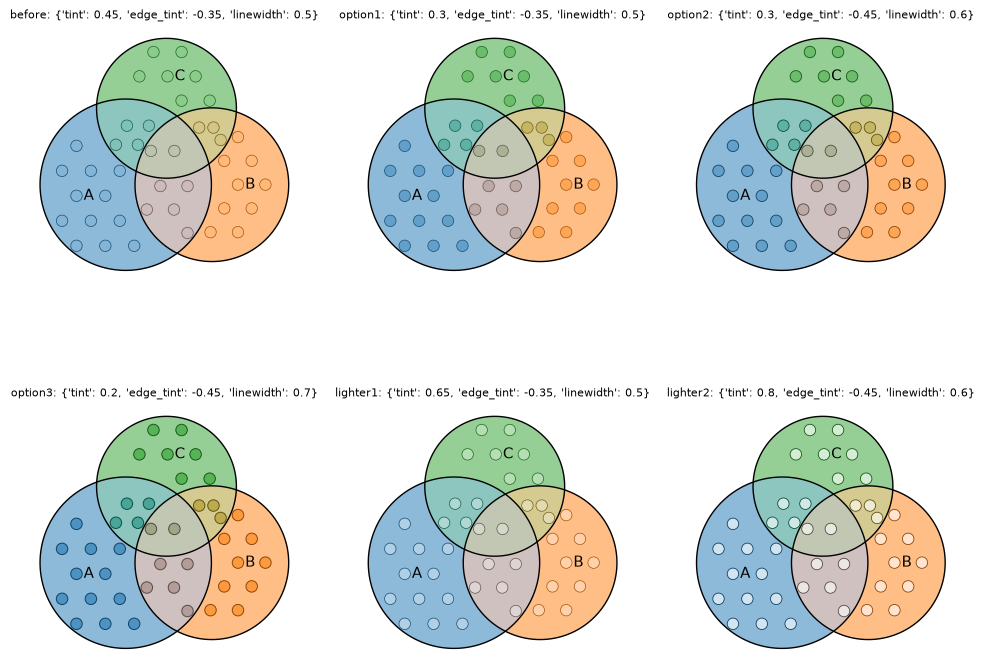

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(12, 9))
axes = axes.flat
for ax, (name, style) in zip(axes, variants.items()):
    fit.plot(ax=ax, glyphs=style)
    ax.set_title(f"{name}: {style}", fontsize=8)
    single, sax = plt.subplots(figsize=(4, 4))
    fit.plot(ax=sax, glyphs=style)
    single.savefig(out / f"{name}_static.png", dpi=150, bbox_inches="tight")
    plt.close(single)
plt.show()

before {'tint': 0.45, 'edge_tint': -0.35, 'linewidth': 0.5}


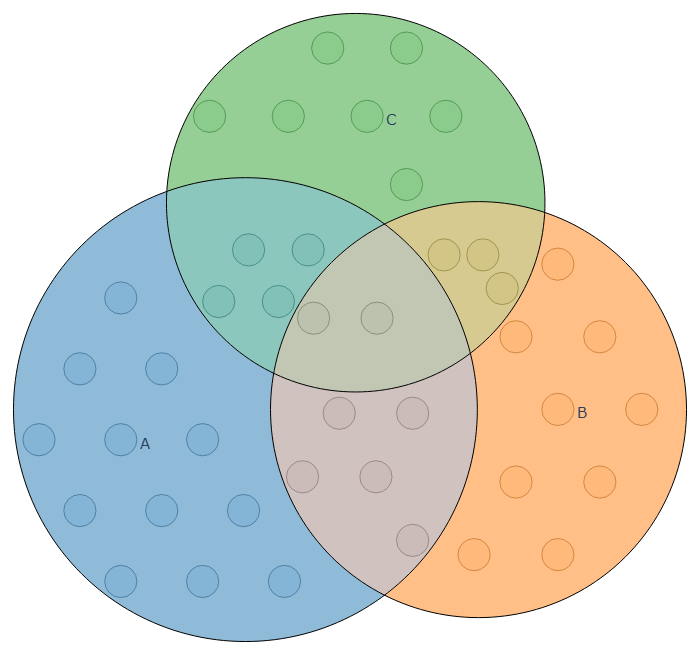

option1 {'tint': 0.3, 'edge_tint': -0.35, 'linewidth': 0.5}


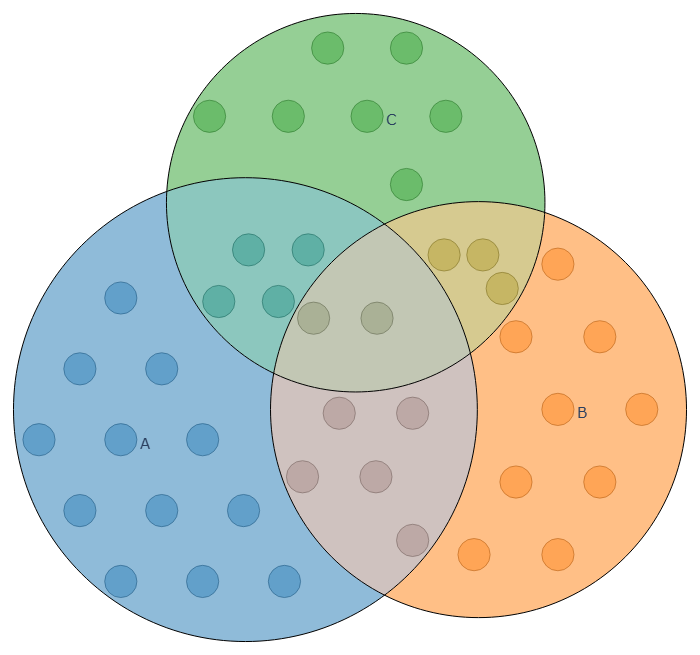

option2 {'tint': 0.3, 'edge_tint': -0.45, 'linewidth': 0.6}


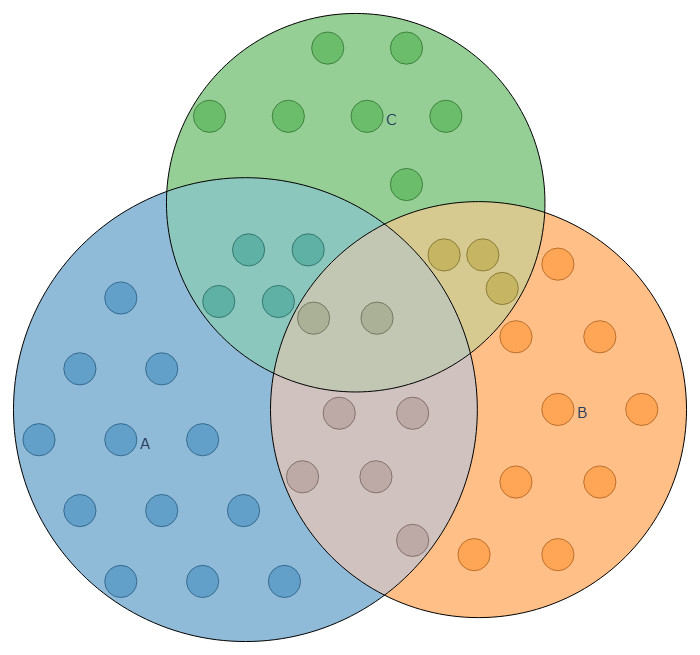

option3 {'tint': 0.2, 'edge_tint': -0.45, 'linewidth': 0.7}


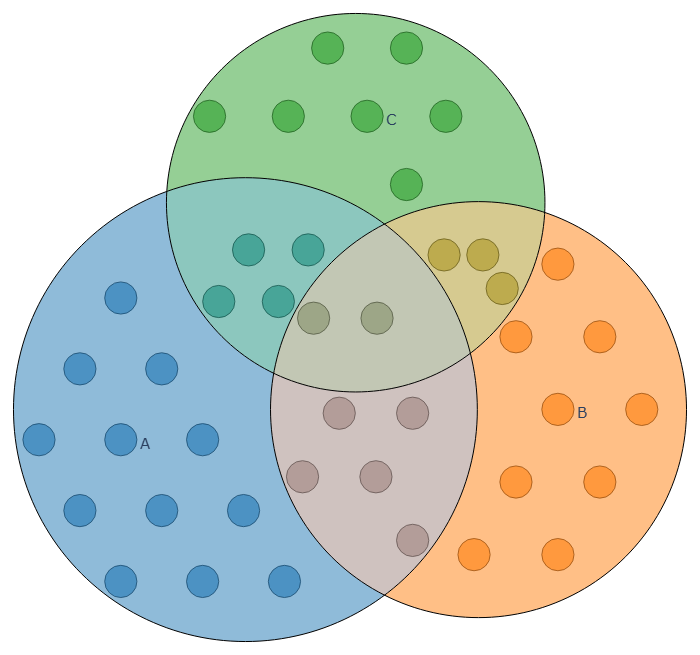

lighter1 {'tint': 0.65, 'edge_tint': -0.35, 'linewidth': 0.5}


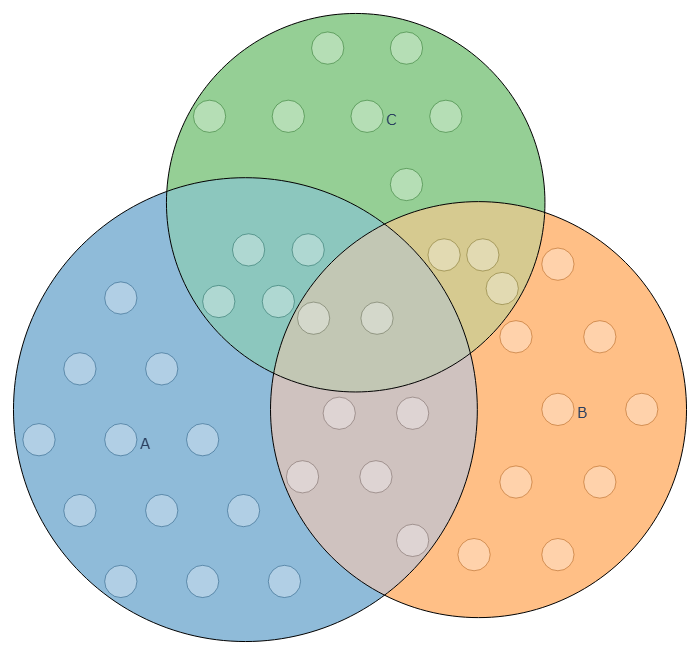

lighter2 {'tint': 0.8, 'edge_tint': -0.45, 'linewidth': 0.6}


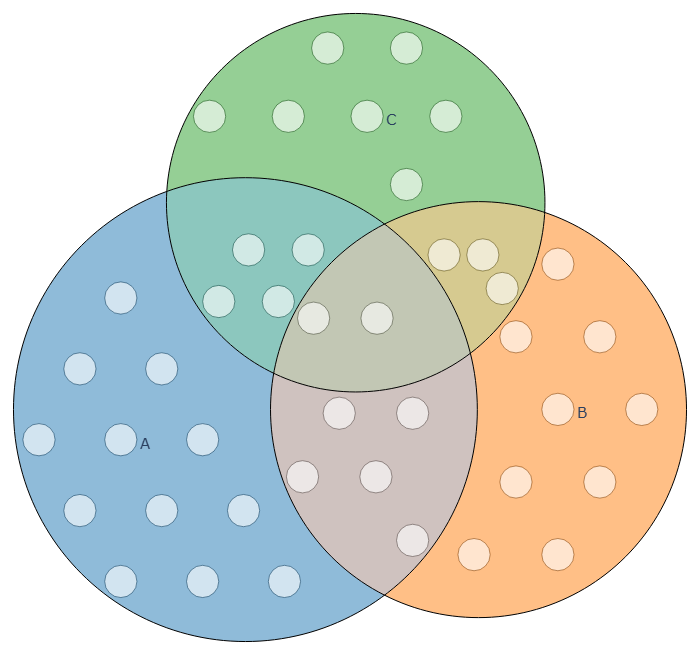

In [3]:
for name, style in variants.items():
    path = out / f"{name}_plotly.png"
    fit.plot_plotly(glyphs=style).write_image(path)
    print(name, style)
    display(Image(str(path), width=320))